# Tumor EDA

The tumor object is inspected without integration: QC by chemistry,
donor/chemistry composition, a PCA/UMAP, and the k=100 same-batch fraction.
Donor and chemistry islands dominate, with a median same-batch fraction of 90%.

Reads `data/processed/preprocessed_tumor.h5ad` and writes figures under
`figures/EDA/`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
FIGS = ROOT / "figures" / "EDA"
FIGS.mkdir(parents=True, exist_ok=True)

sc.settings.verbosity = 1
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12})


warnings.filterwarnings(
    "ignore",
    message="constrained_layout not applied because axes sizes collapsed to zero",
)

# QC metrics

In [2]:
adata = ad.read_h5ad(DATA / "preprocessed_tumor.h5ad")
adata.var["mt"] = adata.var["gene_symbol"].str.startswith(("MT-", "mt-"))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata.shape

(108131, 28617)

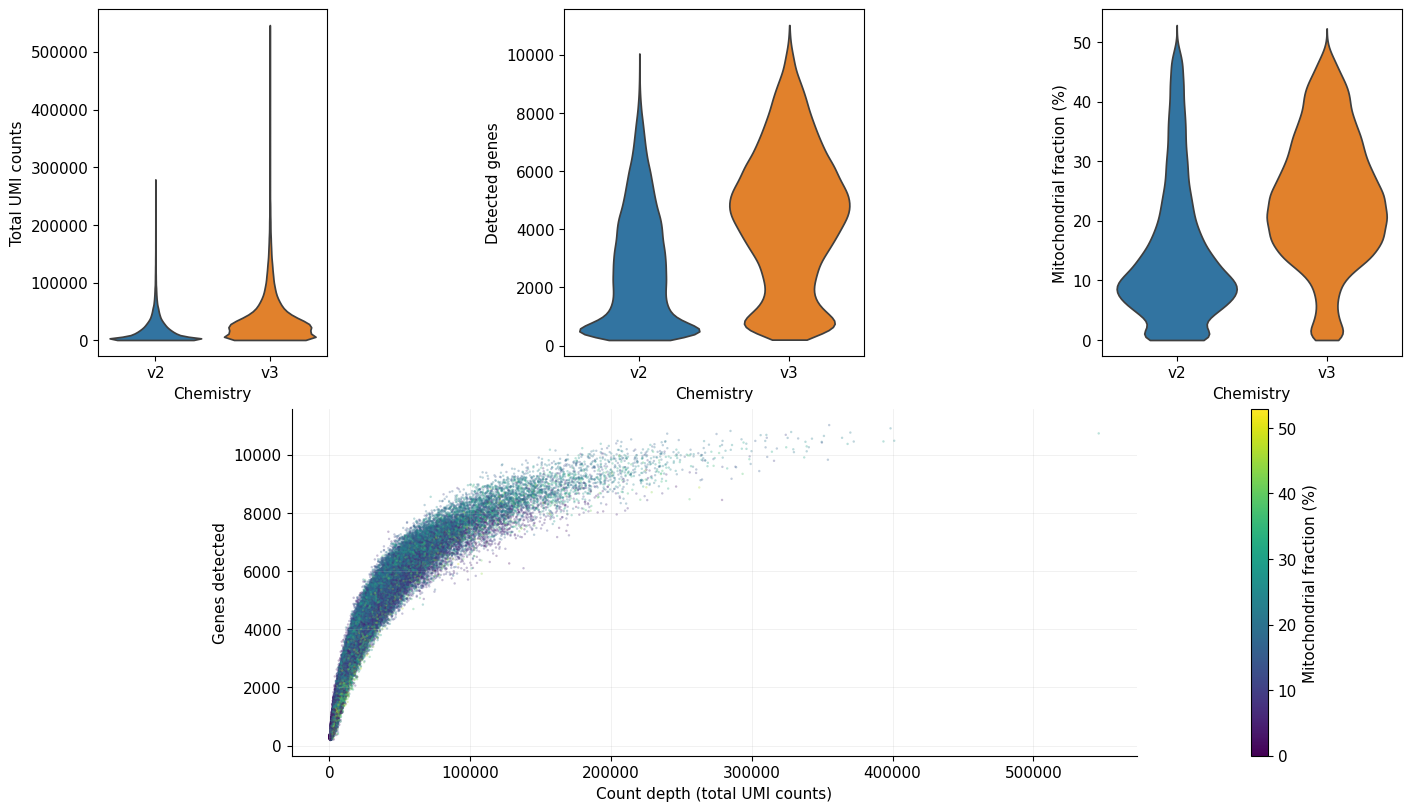

In [3]:
qc_labels = ["Total UMI counts", "Detected genes", "Mitochondrial fraction (%)"]

fig = plt.figure(figsize=(14, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 6)
ax_violins = [fig.add_subplot(gs[0, 2 * i:2 * i + 2]) for i in range(3)]
ax_depth = fig.add_subplot(gs[1, 1:5])

for ax, key, lab in zip(ax_violins, ["total_counts", "n_genes_by_counts", "pct_counts_mt"], qc_labels):
    sc.pl.violin(adata, key, groupby="chemistry", ax=ax, show=False, stripplot=False)
    ax.set_ylabel(lab)
    ax.set_xlabel("Chemistry")

counts = adata.obs["total_counts"].to_numpy()
genes = adata.obs["n_genes_by_counts"].to_numpy()
mito = adata.obs["pct_counts_mt"].to_numpy()

order = np.random.default_rng(0).permutation(len(counts))
pts = ax_depth.scatter(counts[order], genes[order], c=mito[order], s=3, alpha=0.3, linewidths=0, cmap="viridis")
ax_depth.set(xlabel="Count depth (total UMI counts)", ylabel="Genes detected")
ax_depth.spines[["top", "right"]].set_visible(False)
ax_depth.grid(alpha=0.25, linewidth=0.5)
cbar = fig.colorbar(pts, ax=ax_depth, label="Mitochondrial fraction (%)")
cbar.solids.set(alpha=1.0)

plt.savefig(FIGS / "EDA_tumor_qc.png", dpi=200, bbox_inches="tight")

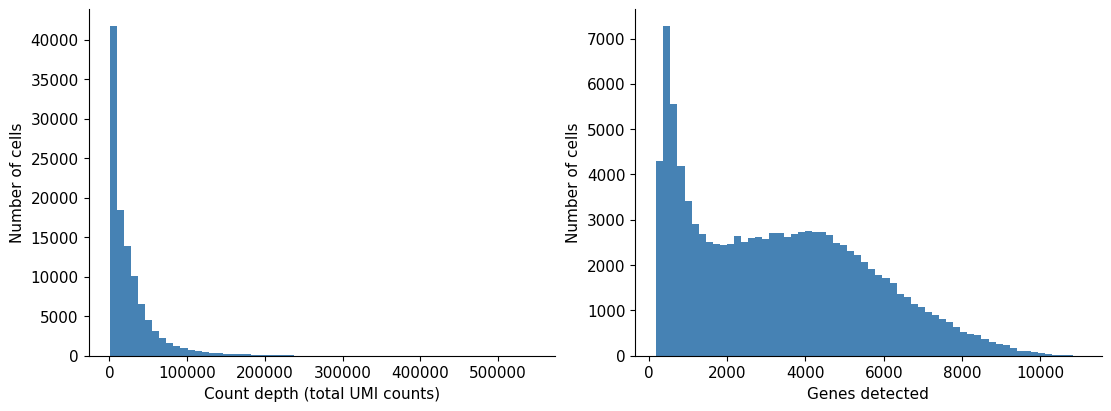

In [4]:
counts = adata.obs["total_counts"].to_numpy()
genes = adata.obs["n_genes_by_counts"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].hist(counts, bins=60, color="steelblue")
axes[0].set(xlabel="Count depth (total UMI counts)", ylabel="Number of cells")
axes[1].hist(genes, bins=60, color="steelblue")
axes[1].set(xlabel="Genes detected", ylabel="Number of cells")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.savefig(FIGS / "EDA_tumor_qc_histograms.png", dpi=200, bbox_inches="tight")

# Composition

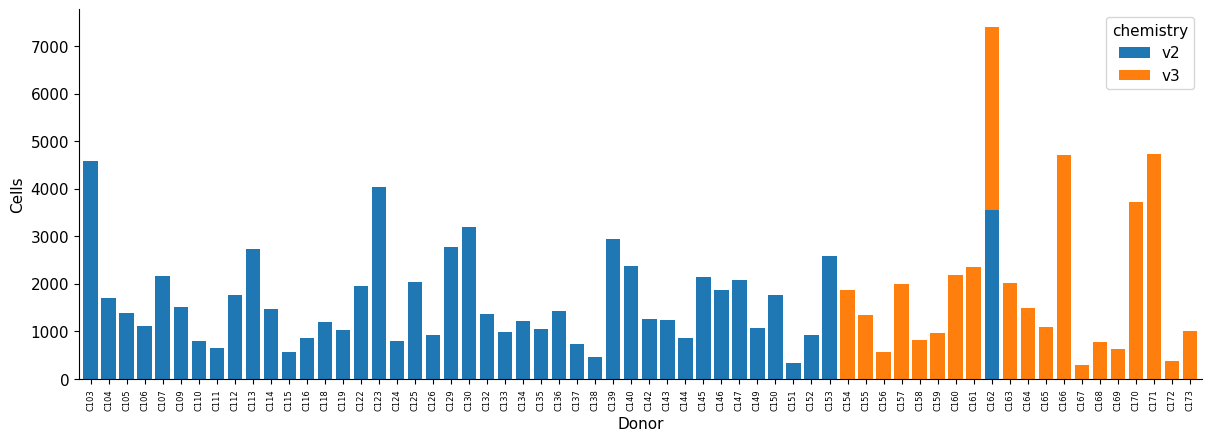

In [5]:
per_donor = adata.obs.groupby(["donor_id", "chemistry"], observed=True).size().unstack(fill_value=0)

fig, ax = plt.subplots(1, 1, figsize=(12, 4.3), constrained_layout=True)
per_donor.plot.bar(ax=ax, stacked=True, width=0.8)
ax.set(xlabel="Donor", ylabel="Cells")
ax.tick_params(axis="x", labelrotation=90, labelsize=6)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig(FIGS / "EDA_tumor_composition.png", dpi=200, bbox_inches="tight")

# Unintegrated representations

In [6]:
sc.pp.highly_variable_genes(adata, n_top_genes=5000, flavor="seurat_v3")
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

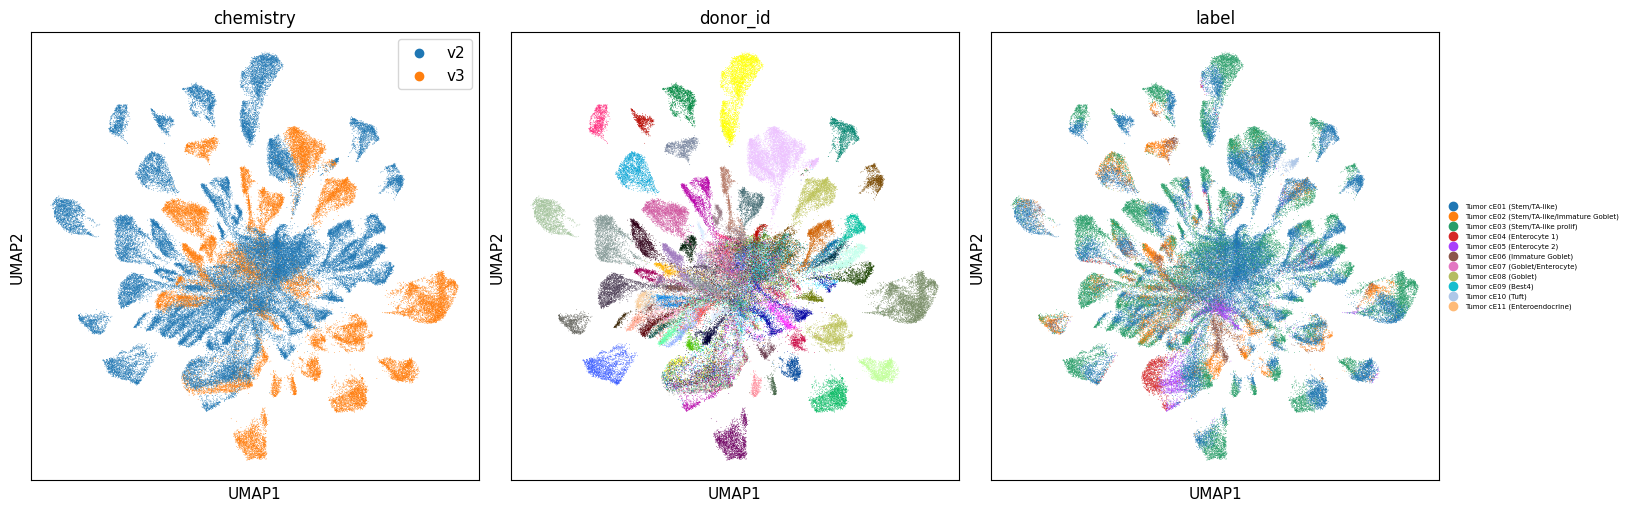

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16.2, 5), constrained_layout=True)
rng = np.random.default_rng(0)
adata = adata[rng.permutation(adata.n_obs)].copy()
sc.pl.umap(adata, color="chemistry", ax=axes[0], show=False, legend_loc="upper right")
sc.pl.umap(adata, color="donor_id", ax=axes[1], show=False, legend_loc=None)
sc.pl.umap(adata, color="label", ax=axes[2], show=False, legend_fontsize=5)
axes[0].get_legend().set_frame_on(True)
for ax in axes:
    ax.set(xlabel="UMAP1", ylabel="UMAP2")

#plt.savefig(FIGS / "EDA_tumor_umap.png", dpi=200, bbox_inches="tight")

k = 100
median same-batch kNN fraction: 0.900
cells with all kNN in same batch: 24.8 %


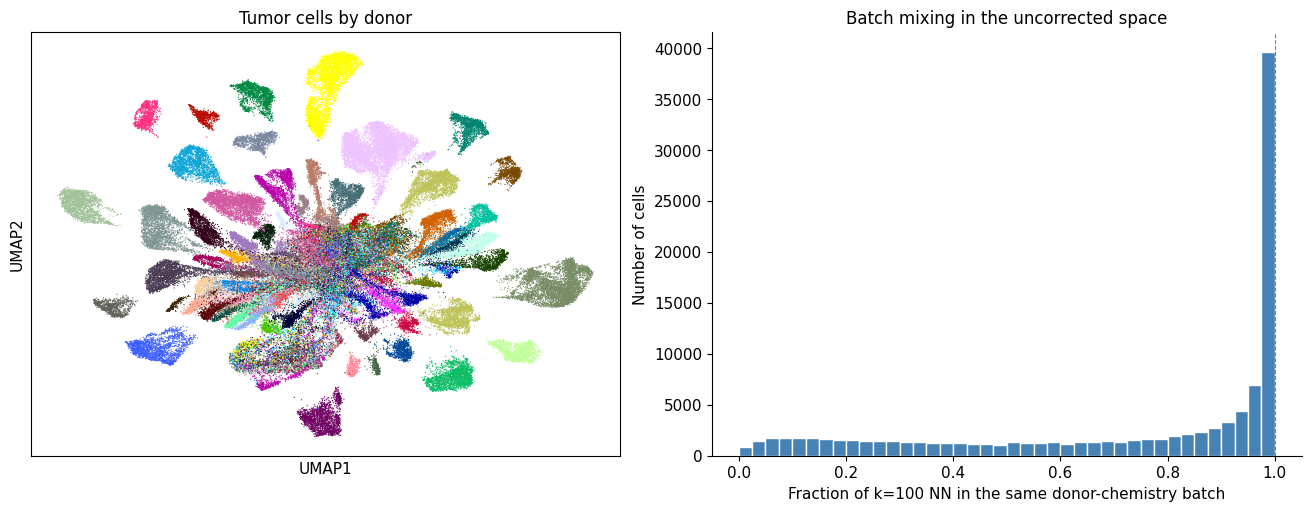

In [8]:
# Fig B: tumor UMAP by donor  +  kNN same-batch fraction (confounding)

# ---- input: neighborhood size ----
K = 100  # number of nearest neighbors used for the mixing metric

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

# --- left: UMAP colored by donor (sc.pl.umap) ---
obs = adata.obs
rng = np.random.default_rng(0)
d = adata[rng.permutation(adata.n_obs)].copy()

sc.pl.umap(d, color="donor_id", ax=axes[0], show=False,
           size=3, legend_loc=None)
axes[0].set_title("Tumor cells by donor")

# --- right: fraction of k nearest neighbors sharing the cell's batch ---
sc.pp.neighbors(adata, n_neighbors=K)        # graph on the uncorrected space at the chosen k
conn = adata.obsp["connectivities"]
batch = obs["batch"].astype(str).to_numpy()

rows, cols = conn.nonzero()
same = (batch[rows] == batch[cols]).astype(float)
num = np.bincount(rows, weights=same, minlength=adata.n_obs)
den = np.bincount(rows, minlength=adata.n_obs)
frac = num / np.maximum(den, 1)

axes[1].hist(frac, bins=40, range=(0, 1), color="steelblue", edgecolor="white")
axes[1].axvline(1.0, color="0.5", ls="--", lw=0.8)
axes[1].set(xlabel=f"Fraction of k={K} NN in the same donor-chemistry batch",
            ylabel="Number of cells", title="Batch mixing in the uncorrected space")
axes[1].spines[["top", "right"]].set_visible(False)

print(f"k = {K}")
print(f"median same-batch kNN fraction: {np.median(frac):.3f}")
print(f"cells with all kNN in same batch: {(frac == 1).mean() * 100:.1f} %")

plt.savefig(FIGS / "EDA_tumor_umap.png", dpi=200, bbox_inches="tight")

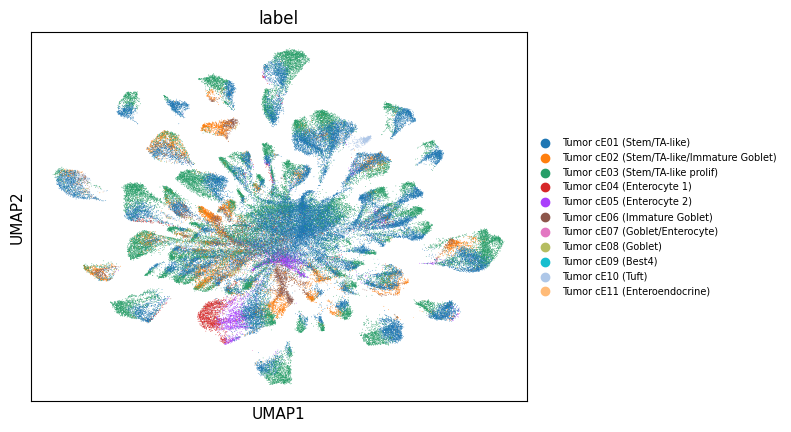

In [9]:
rng = np.random.default_rng(0)
d = adata[rng.permutation(adata.n_obs)].copy()
sc.pl.umap(
    d, color="label", legend_fontsize=7, show=False
).figure.savefig(FIGS / "EDA_tumor_label_umap.png")

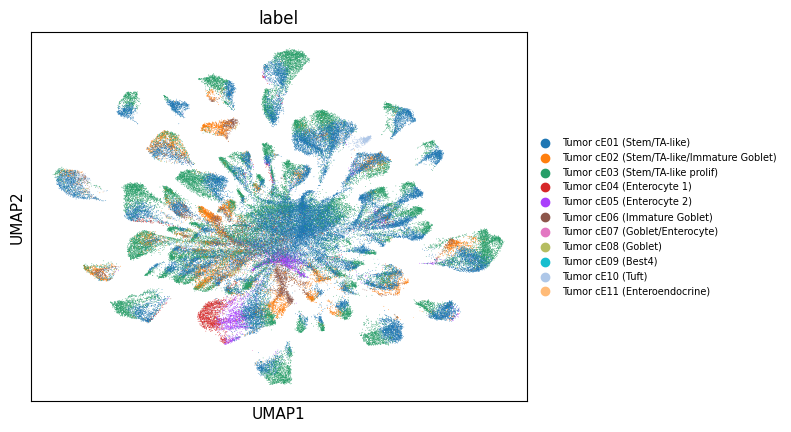

In [10]:
sc.pl.umap(
    d, color="label", legend_fontsize=7, show=False
).figure.savefig(FIGS / "EDA_tumor_label_umap.pdf")

# Metrics

In [11]:
obs = adata.obs

print("Tumor EDA metrics")

n_cells, n_donors = len(obs), obs["donor_id"].nunique()
print(f"cells: {n_cells} | donors: {n_donors}")

per_donor = obs.groupby("donor_id", observed=True).size()
print(f"cells per donor: min {per_donor.min()}, max {per_donor.max()}, median {per_donor.median()}")
print()

per_donor_chem = obs.groupby(["donor_id", "chemistry"], observed=True).size().unstack(fill_value=0)
v2_only = int(((per_donor_chem["v2"] > 0) & (per_donor_chem["v3"] == 0)).sum())
v3_only = int(((per_donor_chem["v3"] > 0) & (per_donor_chem["v2"] == 0)).sum())
both = int(((per_donor_chem["v2"] > 0) & (per_donor_chem["v3"] > 0)).sum())
print(f"donors: {v2_only} v2-only, {v3_only} v3-only, {both} both")
print("donors sequenced with both chemistries:")
print(per_donor_chem[(per_donor_chem > 0).all(axis=1)])
print()

print("QC medians per chemistry:")
print(obs.groupby("chemistry", observed=True)[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].median().round(1))
print()

print("cells per tumor state label and number of donors containing the state:")
lab = obs.groupby("label", observed=True).agg(n_cells=("donor_id", "size"), n_donors=("donor_id", "nunique"))
print(lab)
print("cells per chemistry:")
chem = obs["chemistry"].value_counts()
print(chem)
print()
print("chemistry shares (%):")
print((obs["chemistry"].value_counts(normalize=True) * 100).round(1))
print()

print("cells with mitochondrial fraction > 30 %:")
mt_hi = (obs["pct_counts_mt"] > 30).sum()
print(f"{mt_hi} ({100 * mt_hi / len(obs):.1f} %) of {len(obs)} cells")
print()

print("cells and donors per MMR status:")
mmr = obs.groupby("mmr_status", observed=True).agg(n_cells=("donor_id", "size"), n_donors=("donor_id", "nunique"))
mmr["share_%"] = (mmr["n_cells"] / len(obs) * 100).round(1)
print(mmr)
print()

donor_chem_mmr = obs.groupby(["donor_id", "mmr_status"], observed=True)["chemistry"].apply(lambda s: "+".join(sorted(set(s)))).reset_index(name="chem_combo")
print("donors per MMR status and chemistry combination:")
print(donor_chem_mmr.groupby(["mmr_status", "chem_combo"], observed=True).size().unstack(fill_value=0))
print()

print("cells per MMR status and chemistry:")
print(obs.groupby(["mmr_status", "chemistry"], observed=True).size().unstack(fill_value=0))
print()

print("tumor state share (%) per MMR status:")
lab_mmr = obs.groupby(["mmr_status", "label"], observed=True).size().unstack(fill_value=0)
print((lab_mmr.div(lab_mmr.sum(1), axis=0) * 100).round(1))
print()

print("tumor state share (%) per MMR status within each chemistry:")
for chem in ["v2", "v3"]:
    sub = obs[obs["chemistry"] == chem].groupby(["mmr_status", "label"], observed=True).size().unstack(fill_value=0)
    print(f"--- {chem} ---")
    print((sub.div(sub.sum(1), axis=0) * 100).round(1))

Tumor EDA metrics
cells: 108131 | donors: 62
cells per donor: min 286, max 7402, median 1375.0

donors: 42 v2-only, 19 v3-only, 1 both
donors sequenced with both chemistries:
chemistry    v2    v3
donor_id             
C162       3545  3857

QC medians per chemistry:
           total_counts  n_genes_by_counts  pct_counts_mt
chemistry                                                
v2              10750.0             2426.0           11.3
v3              26964.0             4603.0           23.2

cells per tumor state label and number of donors containing the state:
                                           n_cells  n_donors
label                                                       
Tumor cE01 (Stem/TA-like)                    49252        62
Tumor cE02 (Stem/TA-like/Immature Goblet)     9107        60
Tumor cE03 (Stem/TA-like prolif)             37957        62
Tumor cE04 (Enterocyte 1)                     1892        50
Tumor cE05 (Enterocyte 2)                     3010        62
T